In [80]:
# importing the necessary libraries for data analysis and visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
# Reading the data from a csv file "top_insta_influencers_data.csv".
df=pd.read_csv("top_insta_influencers_data.csv")
df.head()

,rank,channel_info,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_like,total_likes,country
0,1,cristiano,92,3.3k,475.8m,8.7m,1.39%,6.5m,29.0b,Spain
1,2,kyliejenner,91,6.9k,366.2m,8.3m,1.62%,5.9m,57.4b,United States
2,3,leomessi,90,0.89k,357.3m,6.8m,1.24%,4.4m,6.0b,NaN
3,4,selenagomez,93,1.8k,342.7m,6.2m,0.97%,3.3m,11.5b,United States
4,5,therock,91,6.8k,334.1m,1.9m,0.20%,665.3k,12.5b,United States


In [82]:
# getting information about the DataFrame.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   rank               200 non-null    int64
 1   channel_info       200 non-null    str  
 2   influence_score    200 non-null    int64
 3   posts              200 non-null    str  
 4   followers          200 non-null    str  
 5   avg_likes          200 non-null    str  
 6   60_day_eng_rate    200 non-null    str  
 7   new_post_avg_like  200 non-null    str  
 8   total_likes        200 non-null    str  
 9   country            138 non-null    str  
dtypes: int64(2), str(8)
memory usage: 15.8 KB


In [83]:
df.describe()

,rank,influence_score
count,200.000000,200.000000
mean,100.500000,81.820000
std,57.879185,8.878159
min,1.000000,22.000000
25%,50.750000,80.000000
50%,100.500000,84.000000
75%,150.250000,86.000000
max,200.000000,93.000000


In [84]:
# listing all the column names in the DataFrame.
df.columns

Index(['rank', 'channel_info', 'influence_score', 'posts', 'followers',
       'avg_likes', '60_day_eng_rate', 'new_post_avg_like', 'total_likes',
       'country'],
      dtype='str')

In [85]:
# checking the shape of the DataFrame.
df.shape

(200, 10)

In [86]:
# checking for missing values in the DataFrame, which returns a Series with the count of missing values for each column.
df.isnull().sum()   

rank                  0
channel_info          0
influence_score       0
posts                 0
followers             0
avg_likes             0
60_day_eng_rate       0
new_post_avg_like     0
total_likes           0
country              62
dtype: int64

Description: As we can see that there are not any missing value in this dataset so we not need to drop anything.

In [87]:
df[df['country'].isnull()] = df.fillna(df['country'].mode()[0], inplace=True)

Description: As we can see, the code aims to replace missing country names with the most common country in the dataset.

In [88]:
df.isnull().sum()

rank                 0
channel_info         0
influence_score      0
posts                0
followers            0
avg_likes            0
60_day_eng_rate      0
new_post_avg_like    0
total_likes          0
country              0
dtype: int64

Description: As we can see that there are not any missing value in this dataset so we not need to drop anything.

In [89]:
df.duplicated().sum()

np.int64(0)

Description: as we can see that there are not any duplicate value the this dataset so we not need to remove duplicates.

In [90]:
df.drop_duplicates(inplace=True)

Description: As we can see that there are not any duplicate value shown in the code and contributes to the Instagram database exploratory data analysis.

In [91]:
df['posts']=df['posts'].apply(lambda x: int(x) if "k" not in x else int(float(x.replace('k',""))*1000) )

Description: As we can see that Analyzing the Instagram fields used in this cell to explore account, post, or engagement patterns.

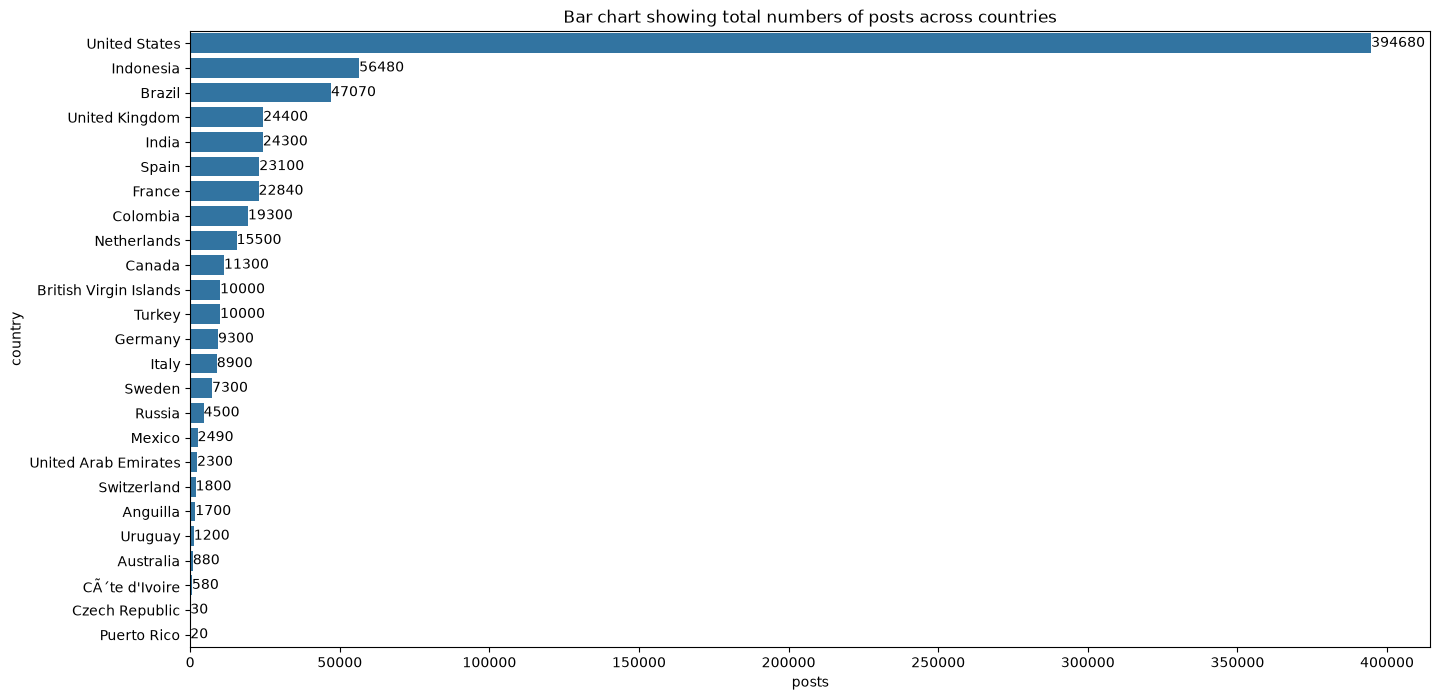

In [92]:
posts_count_on_country=df.groupby(['country'],as_index=False)['posts'].sum()
posts_count_on_country.reset_index(drop=True,inplace=True)
posts_count_on_country.sort_values(['posts'],inplace=True,ascending=False)
plt.figure(figsize=(16, 8))
plt.title("Bar chart showing total numbers of posts across countries")
ax=sns.barplot(y='country', x='posts', data=posts_count_on_country);
ax.bar_label(ax.containers[0])
plt.show()

Description: As we can see that the maximum numbers of post are from united states.

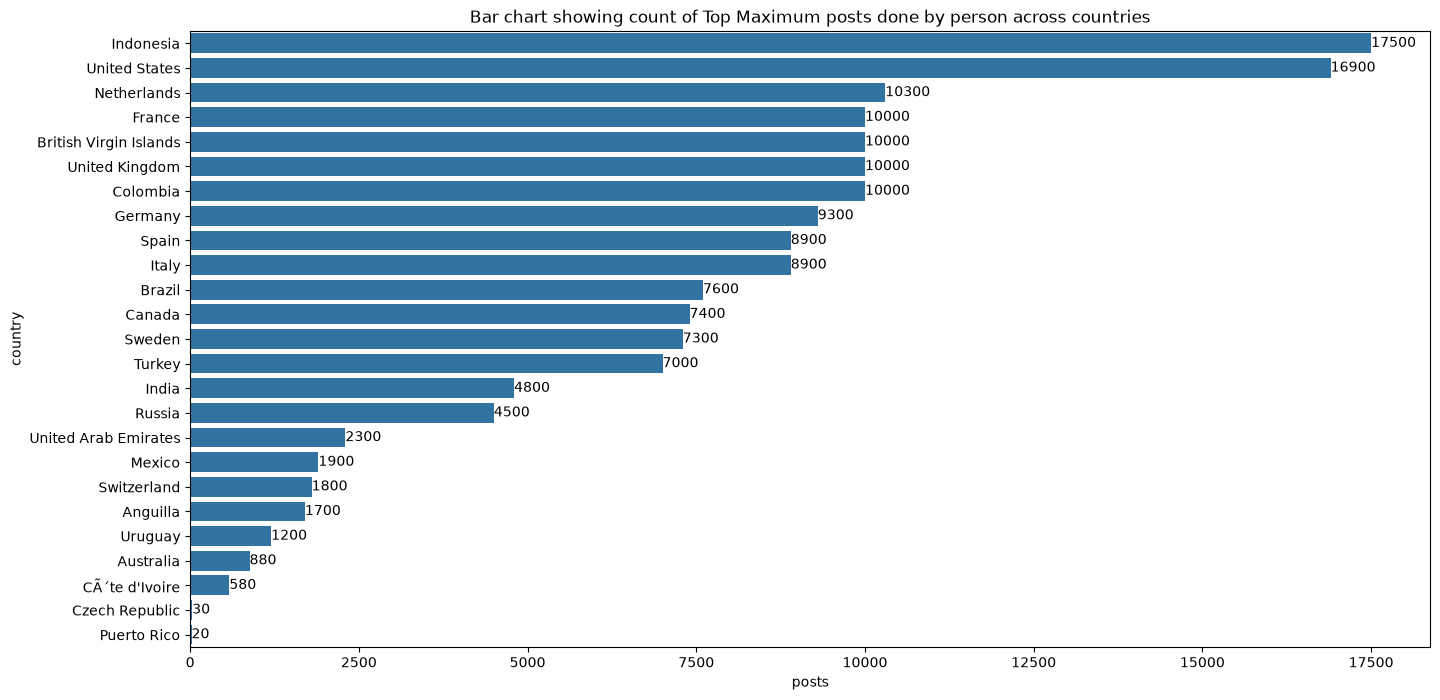

In [93]:
posts_count_on_country=df.groupby(['country'],as_index=False)['posts'].max()
posts_count_on_country.reset_index(drop=True,inplace=True)
posts_count_on_country.sort_values(['posts'],inplace=True,ascending=False)
plt.figure(figsize=(16, 8))
plt.title("Bar chart showing count of Top Maximum posts done by person across countries")
ax=sns.barplot(y='country', x='posts', data=posts_count_on_country);
ax.bar_label(ax.containers[0])
plt.show()

Description: As we can see that the maximum numbers of posts done by a person from indonesia.

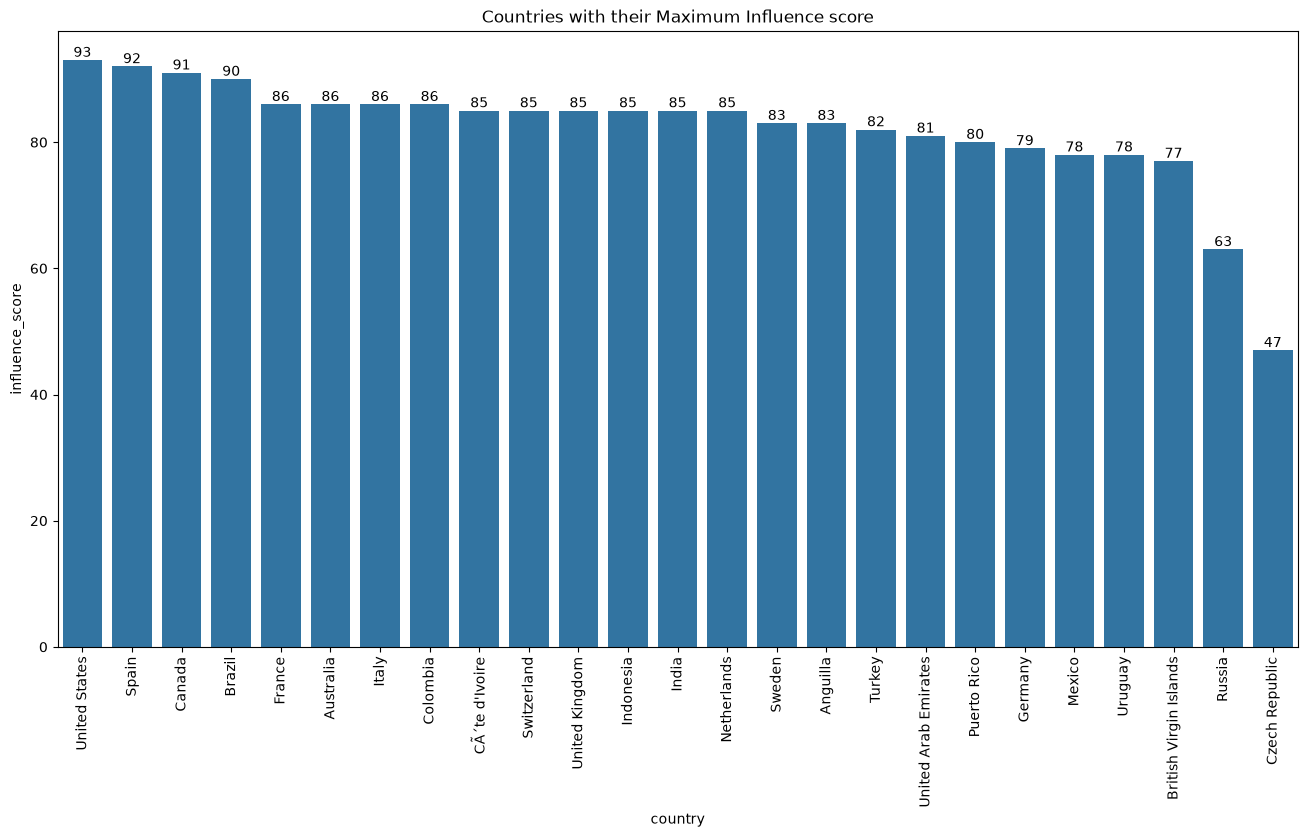

In [94]:
most_influence_country=df.groupby(['country'],as_index=False)['influence_score'].max()
most_influence_country.reset_index(drop=True,inplace=True)
most_influence_country.sort_values(by=['influence_score'],inplace=True,ascending=False)
plt.figure(figsize=(16, 8))
plt.title("Countries with their Maximum Influence score")
ax=sns.barplot(
    data=most_influence_country, x="country", y="influence_score")
ax.bar_label(ax.containers[0])
plt.xticks(rotation='vertical')
plt.show()

Description: As we can see that the maximum influence score are from united states.

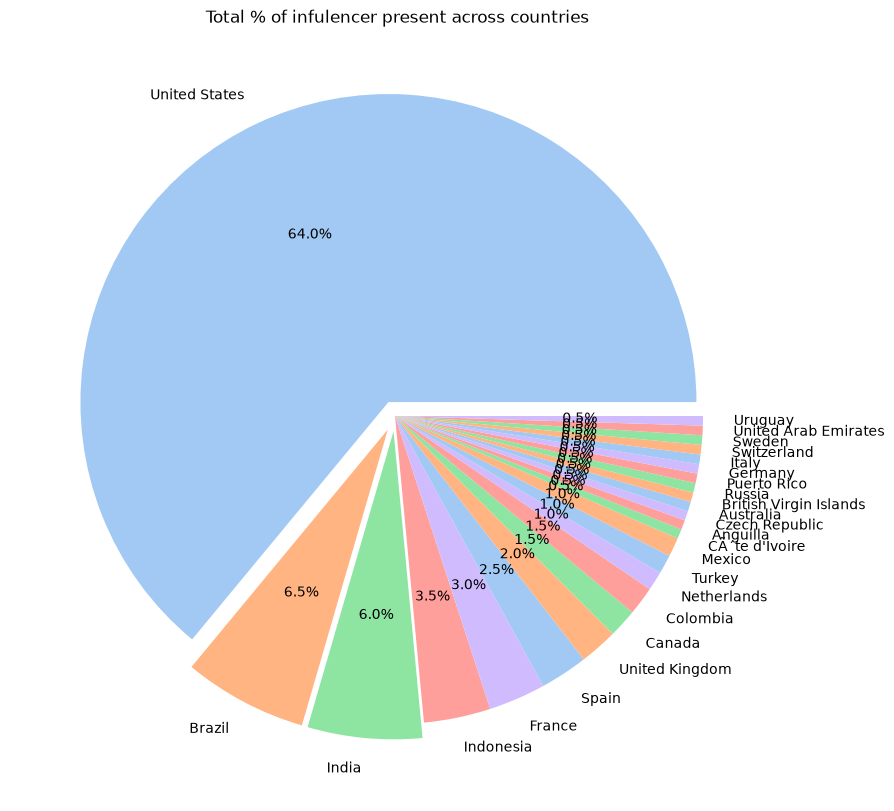

In [95]:
df["Entries"]=1
No_of_infulencer_per_country=df.groupby(["country"],as_index=False)['Entries'].sum()
No_of_infulencer_per_country.sort_values(by=['Entries'],ascending=False,inplace=True)
plt.figure(figsize=(15, 10))
plt.title(" Total % of infulencer present across countries")
explode = No_of_infulencer_per_country['Entries'].apply(lambda x:0.05 if x>10 else 0)
colors = sns.color_palette('pastel')[0:5]
plt.pie(No_of_infulencer_per_country['Entries'].tolist(), labels = No_of_infulencer_per_country["country"].tolist()
        , colors = colors, autopct='%1.1f%%',explode = explode)
plt.show()

Description: As we can see that maximum total percent influencer present from united states.

 Posts Vs Likes Plot for Influencing Countries 


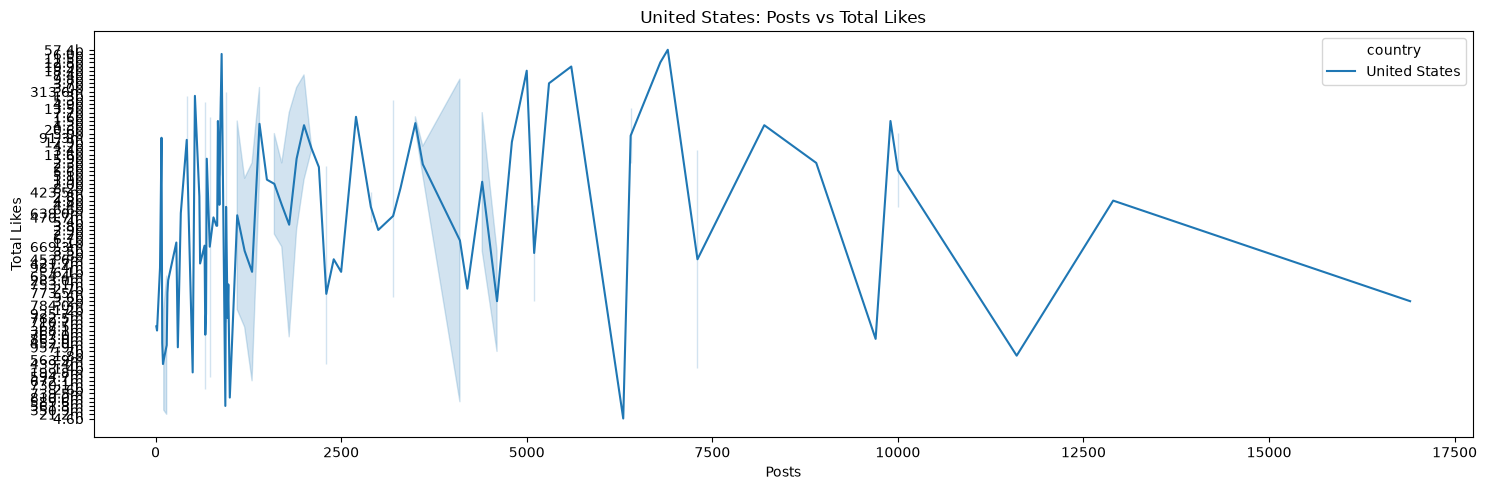

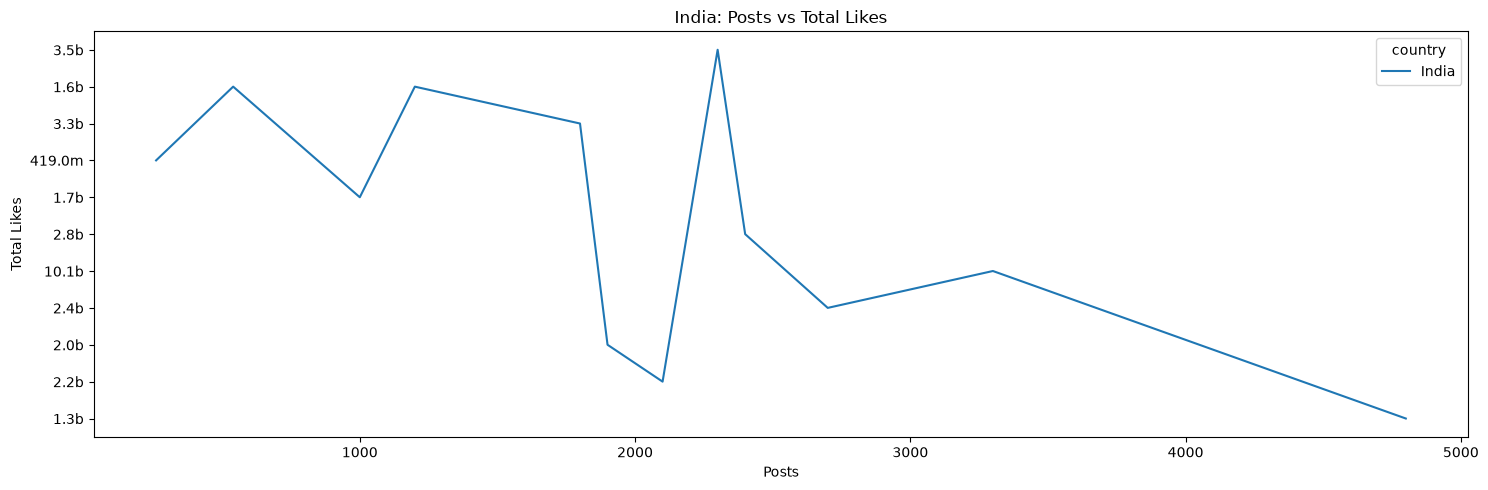

Posting more doesn't necessarily mean you'll get more likes.


In [96]:

print(" Posts Vs Likes Plot for Influencing Countries ")

# United States plot
plt.figure(figsize=(15, 5))
plt.title("United States: Posts vs Total Likes")

USA_data = df[df["country"] == "United States"]

sns.lineplot(data=USA_data, x="posts", y="total_likes", hue="country")

plt.xlabel("Posts")
plt.ylabel("Total Likes")
plt.tight_layout()
plt.show()

# India plot
plt.figure(figsize=(15, 5))
plt.title("India: Posts vs Total Likes")

India_data = df[df["country"] == "India"]

sns.lineplot(data=India_data, x="posts", y="total_likes", hue="country")

plt.xlabel("Posts")
plt.ylabel("Total Likes")
plt.tight_layout()
plt.show()

print("Posting more doesn't necessarily mean you'll get more likes.")


Description: Creating a chart to explore distributions, comparisons, or relationships in the Instagram data.

Followers Vs Likes plot for Top 2 Influencing Countries


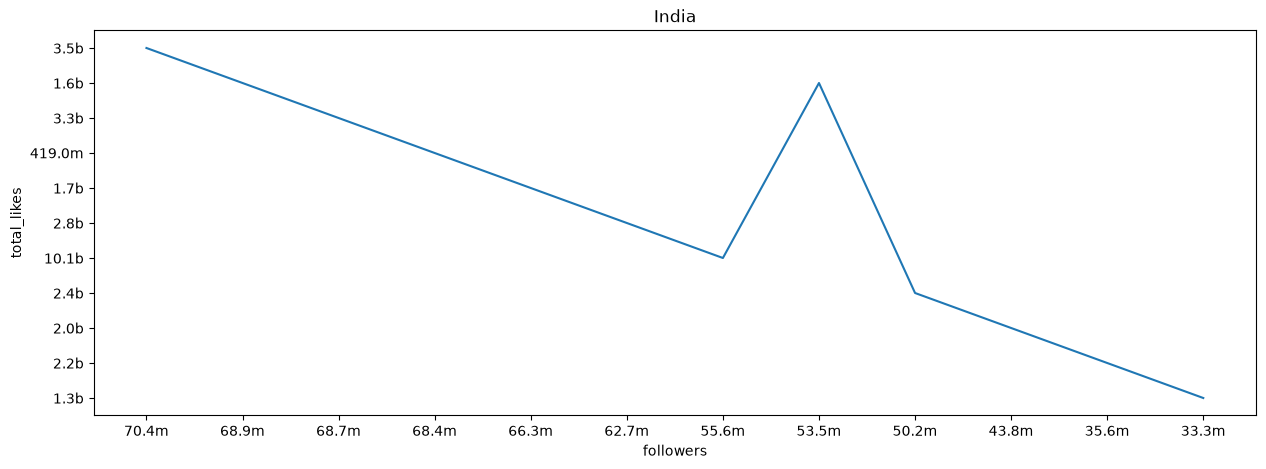

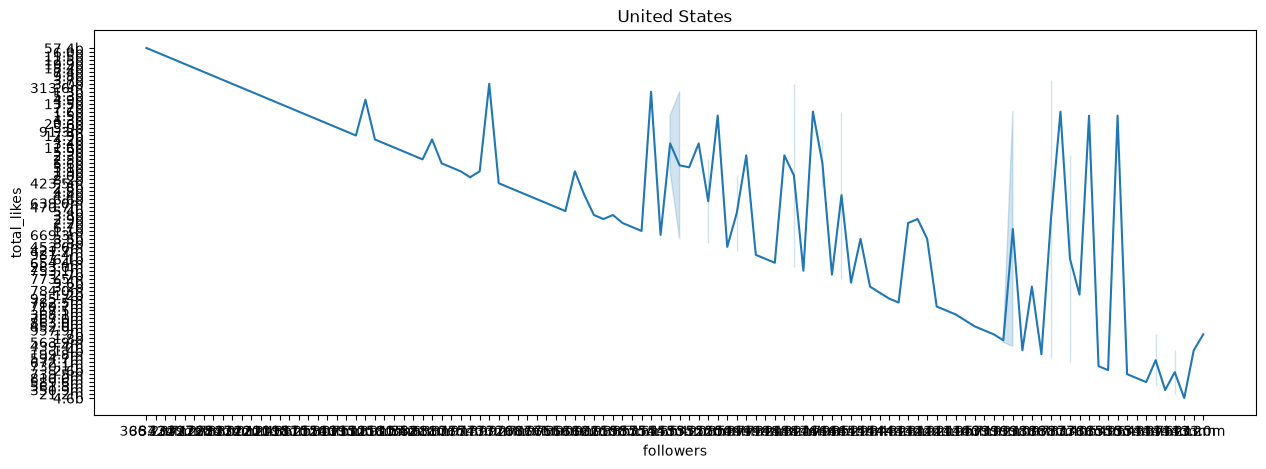

If you have more followers, there is a good probability of getting more likes.


In [97]:
print("Followers Vs Likes plot for Top 2 Influencing Countries")

# India
plt.figure(figsize=(15, 5))
plt.title("India")

India_data = df[df['country'] == "India"]

sns.lineplot(data=India_data, x="followers", y="total_likes")
plt.show()

# United States
plt.figure(figsize=(15, 5))
plt.title("United States")

USA_data = df[df['country'] == "United States"]

sns.lineplot(data=USA_data, x="followers", y="total_likes")
plt.show()

print("If you have more followers, there is a good probability of getting more likes.")

Description: Creating a chart to explore distributions, comparisons, or relationships in the Instagram data.

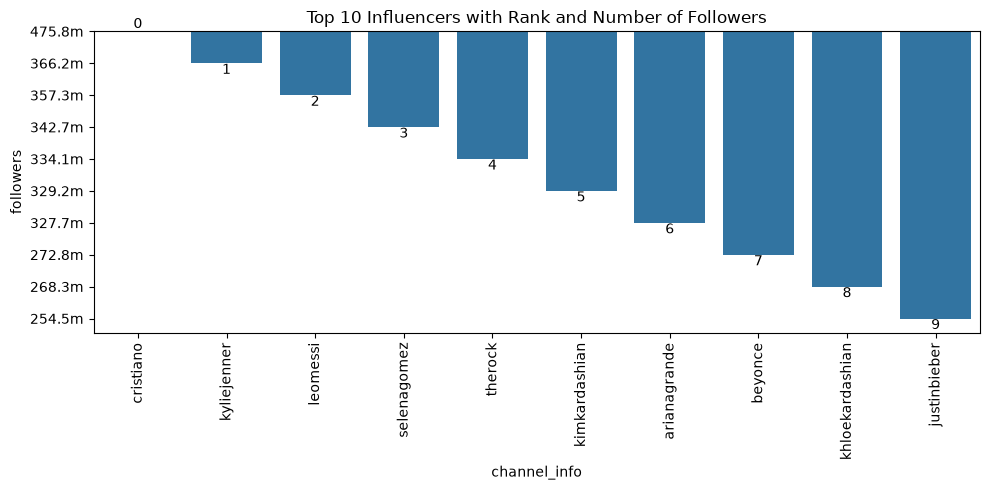

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

plt.title("Top 10 Influencers with Rank and Number of Followers")

ax = sns.barplot(data=df.head(10), x="channel_info", y="followers")

ax.bar_label(ax.containers[0])

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Description: Displaying the first rows of the dataset to inspect its columns and sample records.

ValueError: Could not interpret value `influence_score` for `x`. Value is a string, but `data` was not passed.

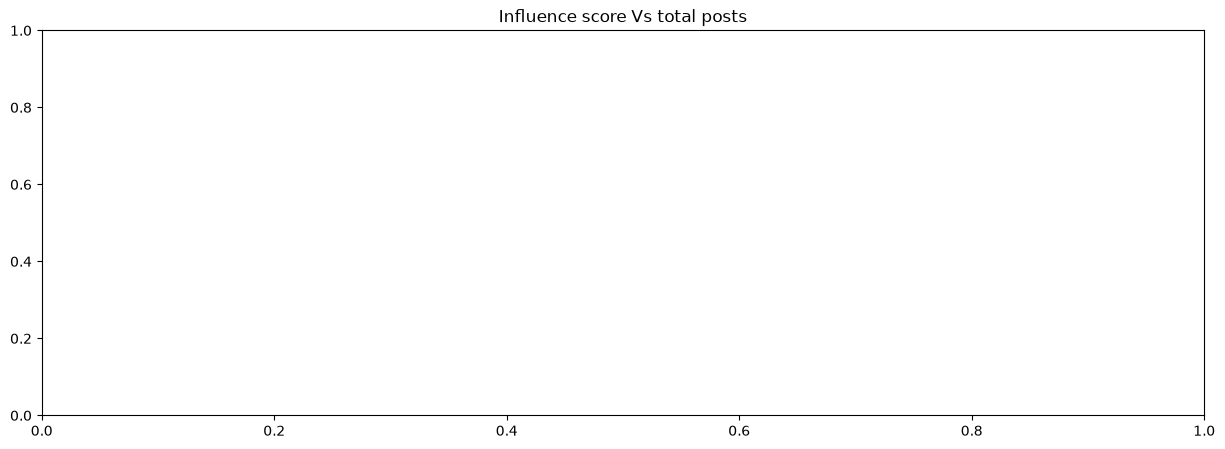

In [ ]:
plt.figure(figsize=(15, 5))
plt.title("Influence score Vs total posts")
sns.lineplot(df=df, x="influence_score", y="posts")
plt.show()

print("People with highest Influence score have decent numbers of post but that doesn't mean they are at top because of \ntheir number of posts")

Description: Creating a chart to explore distributions, comparisons, or relationships in the Instagram data.

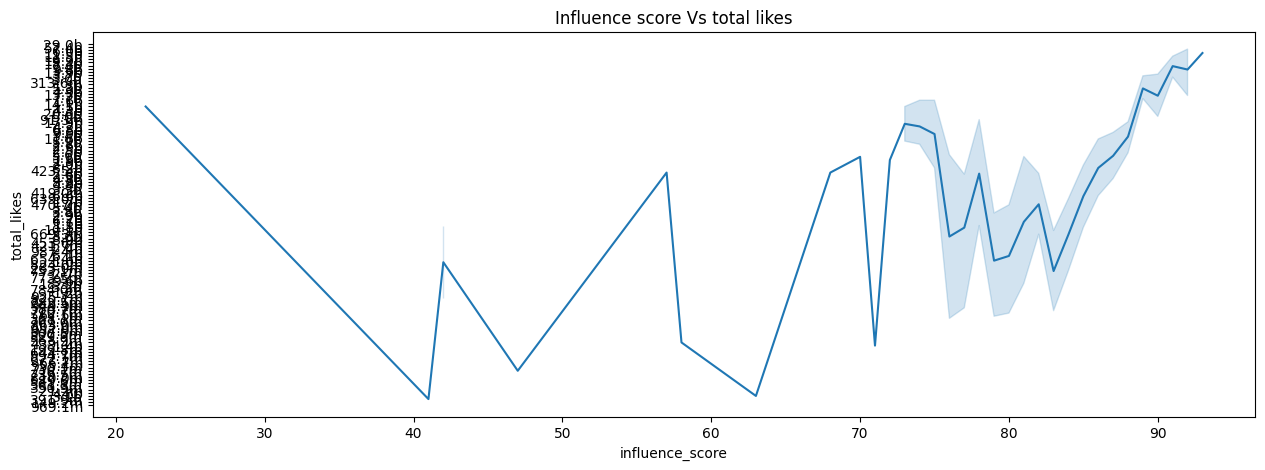

---------------------------------------------------------------------------------------------------------------------
People with highest Influence score have decent numbers of likes but that doesn't mean they are at top because of 
there number of likes
---------------------------------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(15, 5))
plt.title("Influence score Vs total likes")
sns.lineplot(df=df, x="influence_score", y="total_likes")
plt.show()

print("People with highest Influence score have decent numbers of likes but that doesn't mean they are at top because of \ntheir number of likes")

Description: Creating a chart to explore distributions, comparisons, or relationships in the Instagram data.

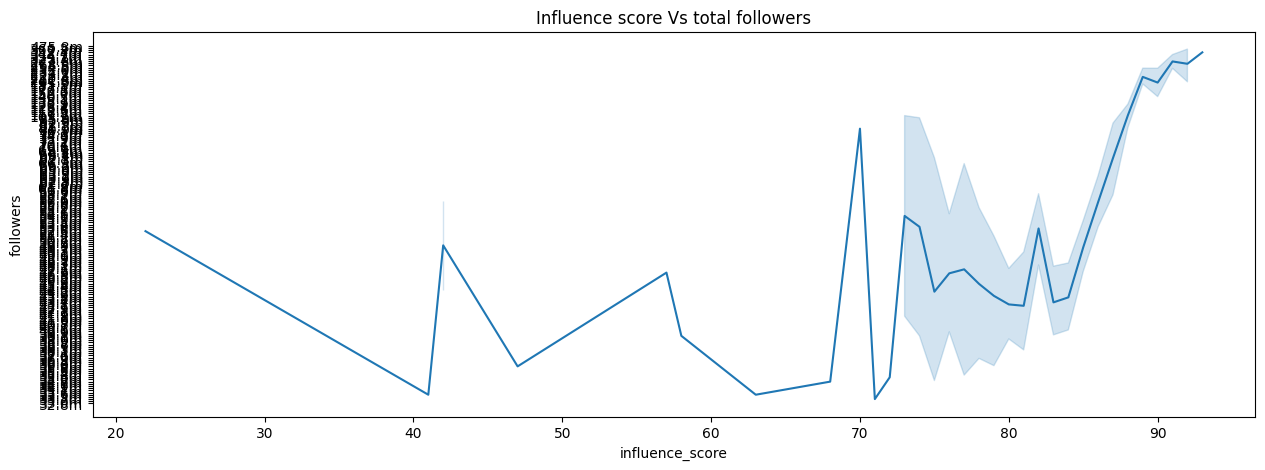

-------------------------------------------------------------------------------------------
People with highest Influence score have high numbers of followers and the graphs proves it
-------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(15,5))
plt.title("Influence score Vs total followers")
sns.lineplot(df=df, x="influence_score", y="followers")
plt.show()

print("People with highest Influence score have high numbers of followers and the graphs proves it")

Description: Creating a chart to explore distributions, comparisons, or relationships in the Instagram data.